# Задание 3. Ансамблевая модель и интерпретация

## Цель
Построить ансамблевую модель с подбором гиперпараметров и проинтерпретировать её.

## Метрика
Основная: Recall
Дополнительные: F1-score, Accuracy

## Обоснование метрики
В задаче прогнозирования оттока важно минимизировать FN (не пропустить уходящего клиента), поэтому используется Recall.

In [98]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, recall_score, f1_score, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

import shap
import matplotlib.pyplot as plt
plt.style.use('default')
RANDOM_STATE = 42

## Загрузка данных

Загружаем исходный датасет и приводим названия колонок к удобному формату.

In [99]:
df = pd.read_excel("../data/Telco_customer_churn.xlsx")
df.columns = [col.strip().replace(" ", "_") for col in df.columns]

df.head()

,CustomerID,Count,Country,State,City,Zip_Code,Lat_Long,Latitude,Longitude,Gender,...,Contract,Paperless_Billing,Payment_Method,Monthly_Charges,Total_Charges,Churn_Label,Churn_Value,Churn_Score,CLTV,Churn_Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


## Очистка числовых признаков

Преобразуем числовые признаки к корректному типу и обрабатываем пропуски.

In [100]:
df['Total_Charges'] = df['Total_Charges'].replace('', '0')
df['Total_Charges'] = pd.to_numeric(df['Total_Charges'], errors='coerce').fillna(0)

numeric_columns = ['Tenure_Months', 'Monthly_Charges', 'Total_Charges', 'CLTV']

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

## Очистка категориальных признаков

Заполняем пропуски и пустые значения категориальных признаков.

In [101]:
categorical_columns = [
    'Gender', 'Senior_Citizen', 'Partner', 'Dependents',
    'Phone_Service', 'Multiple_Lines', 'Internet_Service',
    'Online_Security', 'Online_Backup', 'Device_Protection', 'Tech_Support',
    'Streaming_TV', 'Streaming_Movies', 'Contract', 'Paperless_Billing', 'Payment_Method'
]

for col in categorical_columns:
    df[col] = df[col].fillna('Unknown').replace('', 'Unknown')

## Создание целевой переменной

Преобразуем целевой признак в бинарный формат (1 — клиент уйдёт, 0 — останется).

In [102]:
df['Churn_Binary'] = (df['Churn_Label'] == 'Yes').astype(int)

df['Churn_Binary'].value_counts()

Churn_Binary
0    5174
1    1869
Name: count, dtype: int64

## Формирование признаков

Разделяем данные на признаки (X) и целевую переменную (y).

In [103]:
num_features = numeric_columns
cat_features = categorical_columns

X = df[num_features + cat_features]
y = df['Churn_Binary']

## Разделение на обучающую и тестовую выборки

Используем stratify, так как классы несбалансированы.

In [104]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

## Подготовка Pipeline

Часть предобработки (очистка данных) выполнена заранее.

В Pipeline включены:
- масштабирование числовых признаков
- кодирование категориальных признаков

Это предотвращает утечки данных и обеспечивает корректное применение трансформаций.
Используем ансамблевую модель RandomForestClassifier как более сложную модель.

In [105]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_columns),
    ('cat', categorical_transformer, categorical_columns)
])

In [106]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=RANDOM_STATE))
])

param_dist = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [None, 5, 10, 20, 30],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2', None],
}
search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=param_dist,
    n_iter=20,
    scoring='recall',
    cv=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)
best_model = search.best_estimator_

print("Лучшие гиперпараметры:", search.best_params_)
print(f"Recall на CV: {search.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Лучшие гиперпараметры: {'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': None, 'model__max_depth': 5}
Recall на CV: 0.5478


## Вывод по подбору гиперпараметров

Для улучшения качества модели был проведён подбор гиперпараметров с помощью RandomizedSearchCV.

### Лучшие найденные параметры:

| Параметр | Значение |
|----------|----------|
| n_estimators | 500 |
| min_samples_split | 2 |
| min_samples_leaf | 2 |
| max_features | None |
| max_depth | 5 |

### Результаты кросс-валидации:
**Recall (CV) = 0.5478**

- Оптимальная глубина дерева — 5, что предотвращает переобучение
- Количество деревьев (500) достаточно большое для стабильности модели
- Значения min_samples_split=2 и min_samples_leaf=2 довольно низкие, модель может строить детальные правила

Полученный Recall (0.55) показывает, что модель находит около 55% уходящих клиентов на кросс-валидации. Это базовый уровень, который можно попробовать улучшить дальше.

## Предсказание на тестовой выборке

Получаем предсказания модели на тестовых данных, которые модель не видела во время обучения.
Это позволяет корректно оценить её обобщающую способность.

In [107]:
y_pred = best_model.predict(X_test)

## Оценка качества модели

Оцениваем качество модели с помощью ключевых метрик классификации:
Recall — основная метрика (важно не пропускать уходящих клиентов)
F1-score — баланс precision и recall
Accuracy — общая точность (дополнительная метрика)

In [108]:
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

print("TEST METRICS:")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"Accuracy: {accuracy:.4f}")


TEST METRICS:
Recall: 0.4968
F1-score: 0.5672
Accuracy: 0.7990


## Вывод по этапу оценки модели

На данном этапе была обучена ансамблевая модель `RandomForestClassifier` для задачи бинарной классификации оттока клиентов и проведена её оценка на тестовой выборке.

### Полученные результаты

**Recall = 0.4968** — модель находит около 50% клиентов, склонных к оттоку. Это означает, что значительная часть уходящих клиентов всё ещё не определяется моделью, что критично для данной задачи.

**F1-score = 0.5672** — показывает средний баланс между точностью и полнотой, что говорит об умеренном качестве модели.

**Accuracy = 0.7990** — достаточно высокое значение, однако оно может быть завышено из-за дисбаланса классов и не отражает реальную полезность модели.

### Общий вывод

Несмотря на достаточно высокую Accuracy, модель демонстрирует ограниченную способность выявлять клиентов, склонных к оттоку. Основной проблемой является низкий Recall, что особенно важно в бизнес-задаче удержания клиентов, так как пропуск таких пользователей приводит к прямым потерям.

Таким образом, модель можно рассматривать как базовое решение задачи, однако она требует дальнейшего улучшения за счёт:

- настройки гиперпараметров;
- балансировки классов;
- либо использования более сложных ансамблевых методов.

 ## Интерпретация модели

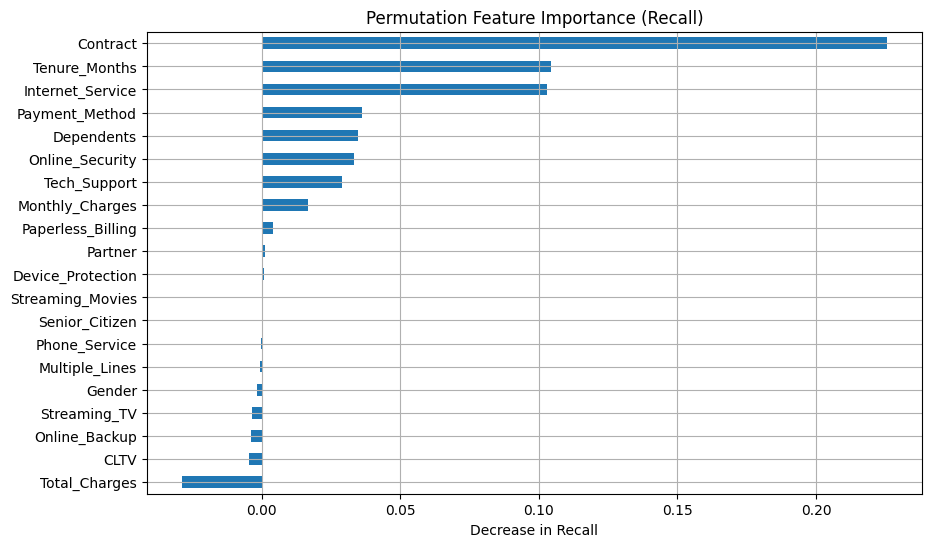

In [113]:
result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,  # было: random_state=42
    scoring='recall'
)
importances = pd.Series(result.importances_mean, index=X_test.columns)
importances = importances.sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importances.plot(kind='barh')
plt.title("Permutation Feature Importance (Recall)")
plt.xlabel("Decrease in Recall")
plt.grid()
plt.show()

## Вывод по графику Permutation Feature Importance

График показывает, как падает Recall при случайном перемешивании каждого признака.

### Ключевые наблюдения

**Contract** (~0.22) — самый важный признак с большим отрывом. Модель строит предсказания в первую очередь на его основе.

**Tenure_Months** и **Internet_Service** (~0.10–0.11) — второй эшелон важности. Их вклад в три раза меньше, чем у Contract.

**Payment_Method**, **Dependents**, **Online_Security** (~0.03–0.04) — умеренный вклад.

**Monthly_Charges**, **Paperless_Billing**, **Partner** (~0.01) — слабое влияние.

**Device_Protection**, **Streaming_Movies**, **Senior_Citizen**, **Gender** — около нуля. Модель их игнорирует.

**Total_Charges** (~−0.02), **CLTV**, **Online_Backup** — отрицательные значения. Эти признаки вносят шум.

### Экспертная оценка

Иерархия признаков соответствует бизнес-логике. Contract определяет обязательства клиента: помесячный контракт = низкие барьеры для ухода. Tenure_Months подтверждает, что новые клиенты уходят чаще. Internet_Service важен из-за высокой конкуренции в сегменте Fiber optic.

Нулевое влияние Gender и Senior_Citizen логично — пол и возраст не определяют лояльность в телекоме. Отрицательный вклад Total_Charges и CLTV объясняется их корреляцией с Tenure_Months — они создают мультиколлинеарность.

### Вывод

Модель опирается на 3–4 ключевых признака. Это объясняет невысокий Recall (~0.50): модель не извлекает слабые сигналы из второстепенных признаков. Для улучшения качества стоит удалить шумовые признаки (Total_Charges, CLTV), сбалансировать классы и попробовать градиентный бустинг.

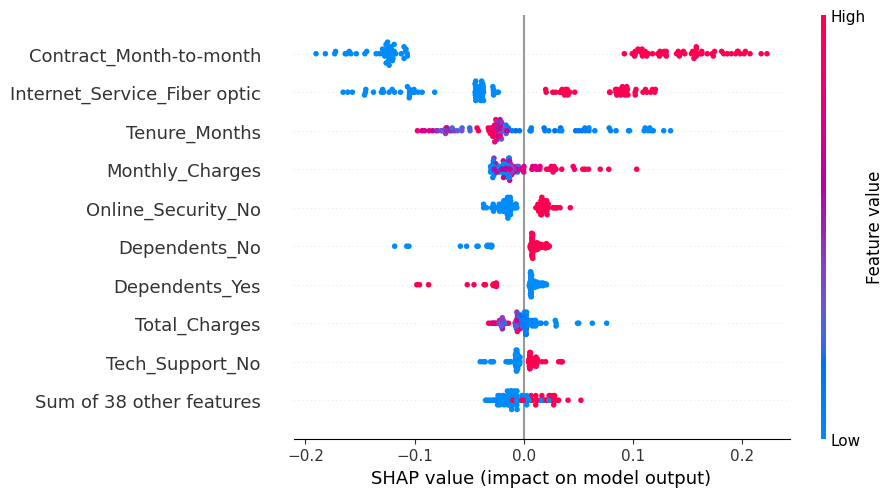

In [110]:
preprocessor_step = best_model.named_steps['preprocessor']
model_step = best_model.named_steps['model']

X_test_transformed = preprocessor_step.transform(X_test)

# Получаем названия признаков после трансформации
num_feature_names = numeric_columns
cat_feature_names = (
    preprocessor_step
    .named_transformers_['cat']
    .named_steps['encoder']
    .get_feature_names_out(categorical_columns)
    .tolist()
)
all_feature_names = num_feature_names + cat_feature_names

# Сэмплируем для ускорения
X_sample = shap.sample(X_test_transformed, 100, random_state=RANDOM_STATE)
X_sample_df = pd.DataFrame(X_sample, columns=all_feature_names)

explainer = shap.Explainer(model_step)
shap_values = explainer(X_sample_df)

shap_values_class1 = shap_values[..., 1]
shap.plots.beeswarm(shap_values_class1)

Клиент с оттоком (индекс 4):


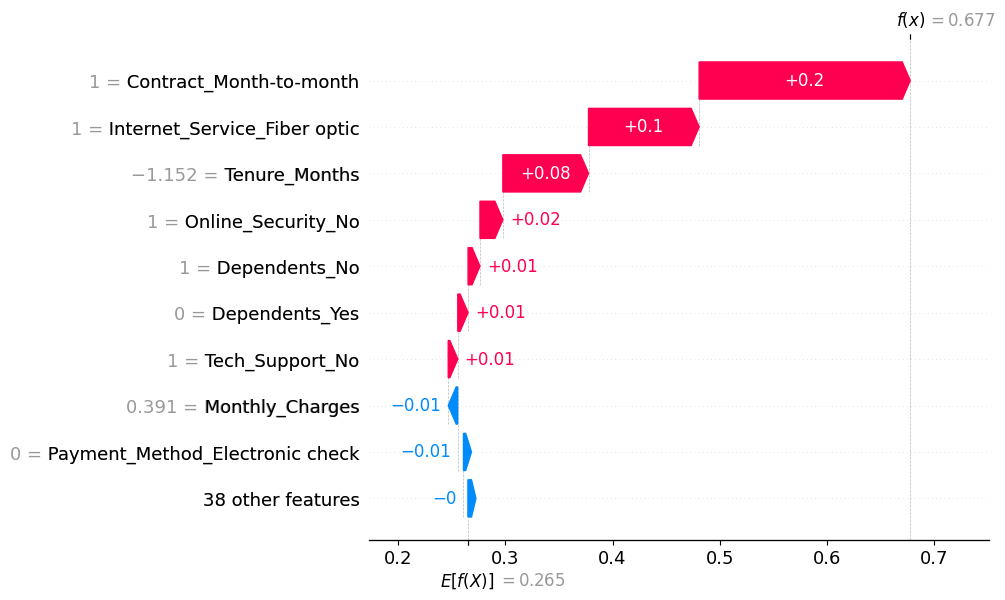

Клиент без оттока (индекс 0):


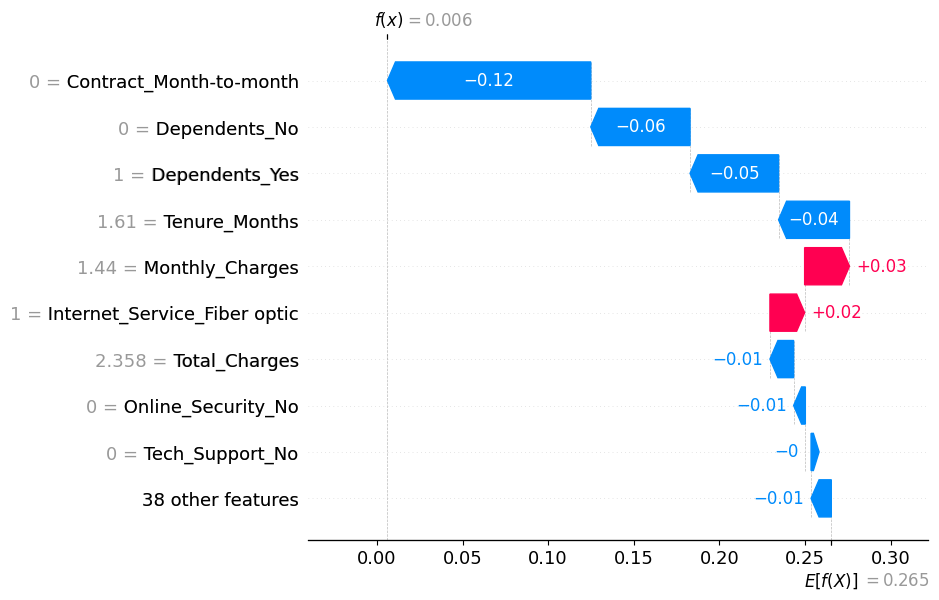

In [111]:
y_sample_pred = best_model.predict(
    X_test.iloc[
        shap.sample(
            np.arange(len(X_test)), 100, random_state=RANDOM_STATE
        )
    ]
)

churn_idx = np.where(y_sample_pred == 1)[0][0]
no_churn_idx = np.where(y_sample_pred == 0)[0][0]

print(f"Клиент с оттоком (индекс {churn_idx}):")
shap.plots.waterfall(shap_values_class1[churn_idx])

print(f"Клиент без оттока (индекс {no_churn_idx}):")
shap.plots.waterfall(shap_values_class1[no_churn_idx])

## Вывод по интерпретации модели (SHAP-анализ)

На данном этапе была проведена интерпретация ансамблевой модели
`RandomForestClassifier` с использованием SHAP — как на уровне
отдельных клиентов, так и по всей выборке целиком.

### 1. Локальная интерпретация — клиент с высоким риском оттока (Waterfall #1)

Предсказание модели: **f(x) = 0.677** — значительно выше базового
уровня **E[f(X)] = 0.265**, что означает высокую вероятность оттока.

Факторы, увеличивающие риск:
- **Contract_Month-to-month = 1** (+0.20) — наибольший вклад.
  Клиент находится на помесячном контракте, что является главным
  триггером оттока.
- **Internet_Service_Fiber optic = 1** (+0.10) — подключение
  оптоволоконного интернета дополнительно увеличивает риск.
- **Tenure_Months = −1.152** (+0.08) — отрицательное стандартизованное
  значение означает короткий стаж клиента, что усиливает риск ухода.
- **Online_Security_No = 1**, **Dependents_No = 1**,
  **Tech_Support_No = 1** — отсутствие дополнительных услуг
  и иждивенцев слабо, но стабильно повышают вероятность оттока.

Факторы, снижающие риск:
- **Monthly_Charges** и **Payment_Method_Electronic check** дают
  небольшой отрицательный вклад (−0.01 каждый), однако он
  недостаточен для компенсации.

**Вывод:** модель обоснованно присваивает этому клиенту высокий
риск — помесячный контракт + короткий стаж + оптоволокно без
защитных услуг — классический профиль уходящего клиента в телекоме.

### 2. Локальная интерпретация — клиент с низким риском оттока (Waterfall #2)

Предсказание модели: **f(x) = 0.006** — существенно ниже базового
уровня **E[f(X)] = 0.265**, что говорит о практически нулевой
вероятности оттока.

Факторы, снижающие риск:
- **Contract_Month-to-month = 0** (−0.12) — клиент не на помесячном
  контракте, что является главным защитным фактором.
- **Dependents_No = 0** и **Dependents_Yes = 1** (−0.06 и −0.05) —
  наличие иждивенцев снижает склонность к смене оператора.
- **Tenure_Months = 1.61** (−0.04) — высокий стаж клиента
  дополнительно удерживает его.

Факторы, незначительно повышающие риск:
- **Monthly_Charges = 1.44** (+0.03) и
  **Internet_Service_Fiber optic = 1** (+0.02) — высокий счёт
  и оптоволокно создают лёгкое давление в сторону оттока, но
  перекрываются защитными факторами.

**Вывод:** модель корректно идентифицирует лояльного клиента —
долгосрочный контракт, длительный стаж и наличие семьи формируют
устойчивый профиль удержания.

### 3. Глобальная интерпретация (SHAP Beeswarm)

Анализ по всей выборке подтверждает и обобщает локальные наблюдения:

- **Contract_Month-to-month** — безусловно самый важный признак.
  Высокое значение (розовый) → сильный положительный SHAP (до +0.25),
  низкое (синий) → сильный отрицательный SHAP (до −0.2).

- **Internet_Service_Fiber optic** — второй по важности признак.
  Наличие оптоволокна стабильно увеличивает риск оттока.

- **Tenure_Months** — третий по важности.
  Высокие значения (длительный стаж) снижают риск,
  низкие — повышают. Зависимость плавная и монотонная.

- **Monthly_Charges** — умеренное влияние.
  Высокие счета незначительно повышают вероятность оттока.

- **Online_Security_No**, **Tech_Support_No**, **Dependents_No** —
  отсутствие услуг и семьи создаёт слабый, но устойчивый риск.

- **Dependents_Yes** — обратная зависимость: наличие иждивенцев
  работает как удерживающий фактор.

Большинство остальных признаков сконцентрированы около нуля
и практически не влияют на решения модели.

### Экспертная оценка

Результаты SHAP-анализа полностью соответствуют бизнес-логике
телекоммуникационной отрасли и подтверждают адекватность модели.

Доминирование **Contract_Month-to-month** закономерно: клиенты
без долгосрочных обязательств могут уйти в любой момент —
это фундаментальная закономерность retention-менеджмента в телекоме,
хорошо известная на практике.

Высокая значимость **Tenure_Months** также ожидаема: чем дольше
клиент пользуется услугами, тем выше его инерция и лояльность —
это соответствует концепции «кривой удержания» в CRM.

**Internet_Service_Fiber optic** как фактор риска объясняется
высокой конкуренцией в этом сегменте и повышенными ожиданиями
клиентов к качеству сервиса — они чаще сравнивают предложения
и готовы переходить к конкурентам.

Низкая значимость **Gender**, **CLTV** и **Total_Charges**
соответствует ожиданиям: пол не связан с лояльностью,
а суммарные списания во многом дублируют информацию из
`Tenure_Months` и `Monthly_Charges`.

Таким образом, модель выявляет содержательно обоснованные паттерны,
а не случайные корреляции — это подтверждает её пригодность
для практического использования в задаче удержания клиентов.

### Сравнение с моделями из Задания 2

Если сравнивать RandomForest с моделями из предыдущего задания:

| Модель | Recall |
|--------|--------|
| Decision Tree | **0.7914** |
| Logistic Regression | **0.7834** |
| RandomForest (текущий) | **0.50** |

Несмотря на более сложную архитектуру, RandomForest уступает
простым моделям по основной бизнес-метрике. Это объясняется
тем, что в данных присутствуют сильные и линейные зависимости
(Contract, Tenure_Months), которые Decision Tree и Logistic
Regression улавливают напрямую, тогда как RandomForest с
ограниченной глубиной деревьев (`max_depth=5`) может не
полностью их использовать.

**Практический вывод:** для задачи удержания клиентов, где
приоритет — Recall, лучшим выбором из протестированных моделей
остаётся Decision Tree или Logistic Regression. RandomForest
в текущей конфигурации целесообразно использовать как
дополнительный инструмент интерпретации факторов оттока,
а не как основную предсказательную модель.

### Ограничения

- Recall ≈ 0.50 — модель пропускает около половины уходящих
  клиентов, что ограничивает её практическую применимость
  без доработки.
- Для улучшения качества рекомендуется: балансировка классов
  (`class_weight='balanced'`), добавление новых признаков
  (например, количество обращений в поддержку),
  либо переход на градиентный бустинг (LightGBM, XGBoost).

### Итог

Модель RandomForest демонстрирует высокую интерпретируемость
и выявляет содержательно обоснованные паттерны оттока, однако
по качеству предсказания уступает более простым моделям.
В реальной задаче удержания клиентов предпочтение стоит отдавать
Decision Tree или Logistic Regression как более эффективным
по Recall, используя RandomForest как инструмент анализа
и объяснения факторов оттока.